In [1]:
# Lädt das Python-Modul sys für Informationen über die laufende Python-Umgebung.
# Theorie: Ein Notebook führt seinen Code in einem Kernel aus; dessen Umgebung bestimmt die verfügbaren Pakete.
import sys
# Gibt die Python-Version einschließlich Informationen zur Erstellung aus; hilfreich zur Prüfung der Umgebung.
print(sys.version)
# Zeigt den Pfad des Python-Interpreters, den der Kernel tatsächlich verwendet.
# Theorie: Verschiedene virtuelle Umgebungen können unterschiedliche Python- und Paketversionen enthalten.
print(sys.executable)

3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
C:\Users\marcu\anaconda3\python.exe


In [2]:
# Importiert den MNIST-Datenlader aus Keras, der hier über TensorFlow bereitgestellt wird.
# Theorie: MNIST enthält Graustufenbilder handgeschriebener Ziffern mit den Klassen 0 bis 9.
from tensorflow.keras.datasets import mnist
# Importiert pandas unter dem Kurznamen pd für Tabellen und Häufigkeitsanalysen.
# Theorie: DataFrame ist eine zweidimensionale Tabelle, Series eine eindimensionale Datenreihe.
import pandas as pd
# Importiert die Zeichenfunktionen von Matplotlib unter dem Kurznamen plt.
# Theorie: Eine Bildmatrix lässt sich visualisieren, indem Zahlenwerte auf Farben abgebildet werden.
import matplotlib.pyplot as plt

In [3]:
# Lädt MNIST und entpackt die zwei Paare aus Bildern (X) und zugehörigen Klassenlabels (y).
# Falls erforderlich, lädt Keras den Datensatz herunter und speichert ihn lokal zwischen.
# Theorie: Überwachtes Lernen verwendet bekannte Antworten zum Training; separate Testdaten prüfen die Generalisierung.
# Jedes Bild besteht aus 28 x 28 Pixeln mit ursprünglichen Helligkeitswerten von 0 bis 255.
(X_train, y_train), (X_test, y_test) = mnist.load_data()
# Prüft 60.000 Trainingsbilder mit je 28 Zeilen und 28 Spalten.
# Theorie: shape beschreibt die Länge jeder Array-Achse; assert löst bei einer falschen Bedingung AssertionError aus.
assert X_train.shape == (60000, 28, 28)
# Prüft die Form der 10.000 Testbilder; sie werden hier nicht zum Lernen verwendet.
assert X_test.shape == (10000, 28, 28)
# Prüft, dass für jedes Trainingsbild genau ein ganzzahliges Klassenlabel existiert.
# Theorie: (60000,) ist ein Tupel mit einer Dimension; das Komma kennzeichnet das eine Tupel-Element.
assert y_train.shape == (60000,)
# Prüft analog die Anzahl der Testlabels; Bild und Label mit demselben Index gehören zusammen.
assert y_test.shape == (10000,)

In [4]:
# Gibt die Dimensionen der Trainingsbilder aus: (Anzahl Bilder, Höhe, Breite).
# Theorie: Die Formprüfung macht sichtbar, ob Daten und spätere Modelleingabe zusammenpassen.
print("x_train:", X_train.shape)
# Gibt die Dimensionen der Testbilder aus; dieselbe Bildgröße ist für die spätere Verarbeitung nötig.
print("x_test:", X_test.shape)
# Zeigt die Form der Trainingslabels: vor dem One-Hot-Encoding ein Vektor mit 60.000 Einträgen.
print("y_train:", y_train.shape)
# Zeigt die Form der Testlabels: ein Vektor mit 10.000 Einträgen.
print("y_test:", y_test.shape)

x_train: (60000, 28, 28)
x_test: (10000, 28, 28)
y_train: (60000,)
y_test: (10000,)


In [8]:
# Gibt das Trainingsarray als Zahlen aus; NumPy kürzt große Arrays normalerweise mit ... ab.
# Theorie: Ein digitales Graustufenbild ist eine Matrix; 0 steht hier für Schwarz, 255 für Weiß.
# X_train enthält viele solcher Matrizen und ist deshalb dreidimensional; print zeichnet keine Bilder.
print(X_train)

[[[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 ...

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]]


In [10]:
# Gibt die Pixelmatrix des elften Trainingsbildes aus, nicht des ersten Bildes.
# Theorie: Python indiziert ab 0; X_train[10] wählt entlang der ersten Achse das Bild mit Index 10.
# Die übrigen zwei Achsen bleiben erhalten, daher hat das ausgewählte Bild die Form (28, 28).
print(X_train[10])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  42 118 219 166 118 118   6
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 103 242 254 254 254 254 254  66
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  18 232 254 254 254 254 254 238
   70   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0 104 244 254 224 254 254 254
  141   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0 207 254 210 25

In [11]:
# Gibt die Klassenlabels der ersten zehn Trainingsbilder aus.
# Theorie: Der Slice [:10] beginnt bei Index 0 und endet vor Index 10; die Werte sind Ziffernklassen, keine Pixel.
# Diese bekannten Zielwerte bilden beim überwachten Lernen die Referenz für die Vorhersagen.
print(y_train[:10])

[5 0 4 1 9 2 1 3 1 4]


In [12]:
# Wandelt die Labels in eine einspaltige Tabelle um und zählt die Häufigkeit jeder unterschiedlichen Zeile.
# Theorie: Da jede Zeile ein Label enthält, ergeben sich die Anzahlen pro Ziffernklasse, standardmäßig absteigend sortiert.
# Ähnliche Klassenhäufigkeiten erleichtern die Interpretation der Accuracy; dominante Klassen können sie verzerren.
# Als letzter Ausdruck einer Notebook-Zelle wird das Ergebnis automatisch angezeigt.
pd.DataFrame(y_train).value_counts()

0
1    6742
7    6265
3    6131
2    5958
9    5949
0    5923
6    5918
8    5851
4    5842
5    5421
Name: count, dtype: int64

In [13]:
# Formt jedes Bild zu 784 (= 28 * 28) Pixelwerten um und erstellt daraus eine Tabelle.
# Theorie: reshape verändert die Anordnung der Dimensionen, nicht die Pixelwerte oder ihre Reihenfolge.
# -1 lässt NumPy die Anzahl der Zeilen berechnen; die Gesamtzahl der Elemente muss erhalten bleiben.
# Ein DataFrame benötigt hier 2D-Daten: jede Zeile ist ein Bild, jede Spalte eine feste Pixelposition.
# Die ursprüngliche Variable X_train wird durch diese Zuweisung nicht verändert.
Dataframe_x = pd.DataFrame(X_train.reshape(-1, 784))
# Zeigt die Tabelle automatisch als letzten Ausdruck an; große Tabellen werden gekürzt dargestellt.
Dataframe_x

,0,1,2,3,4,5,6,7,8,9,...,774,775,776,777,778,779,780,781,782,783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
59996,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
59997,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
59998,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [14]:
# Ermittelt den Python-Typ von y_train, hier nach dem Laden ein NumPy-Array.
# Theorie: Der Datentyp eines Objekts bestimmt seine verfügbaren Operationen; das ist nicht die Array-Form (shape).
# Da danach noch ein Ausdruck folgt, zeigt Jupyter dieses Ergebnis normalerweise nicht automatisch an.
type(y_train)
# Erstellt eine eindimensionale pandas-Series und zählt die Labels pro Klasse.
# Theorie: Diese Klassenverteilung zeigt, wie ausgewogen die Daten sind; MNIST ist ungefähr, aber nicht exakt ausgewogen.
# Diese Operation erwartet hier die ursprünglichen eindimensionalen Labels vor dem One-Hot-Encoding.
pd.Series(y_train).value_counts()

1    6742
7    6265
3    6131
2    5958
9    5949
0    5923
6    5918
8    5851
4    5842
5    5421
Name: count, dtype: int64

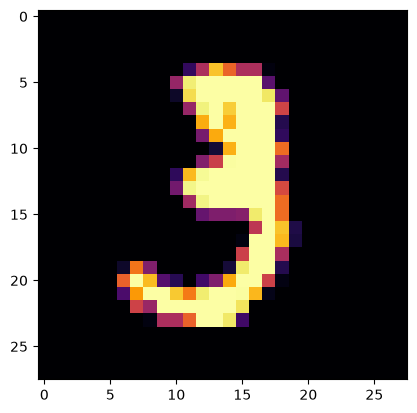

In [15]:
# Zeichnet das elfte Trainingsbild und verwendet ausdrücklich die Farbpalette inferno.
# Theorie: imshow bildet Pixelintensitäten auf Farben ab; inferno ist eine Falschfarbendarstellung, keine Graustufenpalette.
# Die zugrunde liegenden MNIST-Daten bleiben Graustufenwerte; die Farbwahl verändert nur die Anzeige.
# Für eine Graustufenanzeige könnte cmap="gray" verwendet werden. Hier erfolgt die Anzeige vor dem Flattening.
plt.imshow(X_train[10], cmap="inferno")

In [16]:
# Gibt das bekannte Klassenlabel des ersten Trainingsbildes aus, hier die Ziffer 5.
# Theorie: y_train[i] bezeichnet die richtige Ziffer für X_train[i]; Index 0 gehört daher nicht zum oben gezeigten Bild 10.
print(y_train[0])

5


In [19]:
# Importiert Sequential für ein Modell mit einer linearen Abfolge von Schichten.
# Theorie: Die Ausgabe einer Schicht wird jeweils zur Eingabe der nächsten Schicht (Feedforward-Netz).
from tensorflow.keras.models import Sequential
# Importiert Dense für vollständig verbundene Schichten und Input zur Festlegung der Eingabeform.
# Theorie: Ein Dense-Neuron berechnet eine gewichtete Summe plus Bias und wendet darauf eine Aktivierungsfunktion an.
from tensorflow.keras.layers import Dense, Input
# Importiert NumPy als np für numerische Arrays; der Alias wird im vorhandenen Code nicht direkt verwendet.
# Theorie: Die geladenen Bild- und Labeldaten sind NumPy-Arrays und unterstützen z. B. reshape und astype.
import numpy as np
# Importiert die Hilfsfunktion, die ganzzahlige Klassenlabels in One-Hot-Vektoren umwandelt.
# Theorie: Ein Vektor enthält eine 1 an der Position der richtigen Klasse und sonst nur Nullen.
from tensorflow.keras.utils import to_categorical

# Erstellt einen zunächst leeren Container für die nacheinander ausgeführten Schichten.
model = Sequential()

# Definiert 784 Eingabewerte pro Bild; die Batch-Dimension wird in shape nicht angegeben.
# Theorie: 28 * 28 Pixel werden später zu einem Vektor abgeflacht; Input legt die Form fest und hat keine trainierbaren Gewichte.
model.add(Input(shape=(784,)))
# Fügt eine versteckte Schicht mit 64 Neuronen und ReLU-Aktivierung hinzu.
# Theorie: z = W*x + b; ReLU(z) = max(0, z). Diese Nichtlinearität ermöglicht komplexere Zusammenhänge als rein lineare Schichten.
# Jedes Neuron erhält alle 784 Eingaben: 784 * 64 Gewichte + 64 Bias-Werte = 50.240 trainierbare Parameter.
model.add(Dense(64, activation="relu"))
# Fügt zehn Ausgabeneuronen hinzu, jeweils eines für jede Ziffernklasse von 0 bis 9.
# Theorie: Softmax berechnet p_i = exp(z_i) / sum_j(exp(z_j)); die zehn positiven Werte summieren sich zu 1.
# Sie werden als geschätzte Klassenwahrscheinlichkeiten interpretiert; die größte bestimmt typischerweise die Vorhersage.
# Diese Schicht besitzt 64 * 10 Gewichte + 10 Bias-Werte = 650 Parameter.
model.add(Dense(10, activation="softmax"))

# Konfiguriert das Lernverfahren und die Bewertung; compile trainiert das Modell noch nicht.
model.compile(
    # RMSprop passt Gewichte mit Gradienten an und skaliert Schritte anhand eines gleitenden Mittels quadrierter Gradienten.
    # Theorie: Der Optimierer soll die Verlustfunktion durch schrittweise Parameteränderungen minimieren.
    optimizer="rmsprop",
    # Kategoriale Kreuzentropie vergleicht One-Hot-Zielvektoren mit den vorhergesagten Wahrscheinlichkeiten.
    # Theorie: L = -sum_i(y_i * log(p_i)); bei One-Hot-Labels ist das -log(p_richtige_Klasse).
    # Eine kleine Wahrscheinlichkeit für die richtige Klasse führt zu einem großen Verlust.
    loss="categorical_crossentropy",
    # Erfasst den Anteil korrekt klassifizierter Bilder als zusätzliche Metrik.
    # Theorie: Accuracy vergleicht die Klasse mit der höchsten Vorhersage mit der Zielklasse; optimiert wird hier der Loss.
    metrics=["accuracy"]
)
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping = EarlyStopping(
    monitor="val_accuracy",
    patience=10,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "best_mnist_model.keras",
    monitor="val_loss",
    mode = max,
    save_best_only=True
)

# Theorie: Mit loss="sparse_categorical_crossentropy" könnten die Labels stattdessen ganzzahlig bleiben.
# Die gewählte categorical_crossentropy erwartet hier jedoch die nachfolgende One-Hot-Kodierung.
# Zeigt Schichten, Ausgabeformen und Parameterzahlen; insgesamt gibt es 50.890 trainierbare Parameter.
# None in der Ausgabeform bezeichnet die variable Batch-Größe, nicht eine unbekannte Neuronenzahl.
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

## Antworten One Hot enkodieren ##

In [15]:
# Ersetzt die ganzzahligen Trainingslabels durch One-Hot-Vektoren mit zehn Einträgen.
# Theorie: Ziffer 3 wird zu [0, 0, 0, 1, 0, 0, 0, 0, 0, 0]; so passt jedes Label zu den zehn Softmax-Ausgaben.
# Die Form wechselt von (60000,) zu (60000, 10); Klassen werden nicht als geordnete Zahlenabstände behandelt.
y_train = to_categorical(y_train, 10)
# Kodiert die Testlabels nach demselben Schema; ihre Form wird (10000, 10).
# Theorie: Training und spätere Bewertung müssen dieselbe Zuordnung zwischen Vektorposition und Klasse verwenden.
# Diese Zelle einmal nach load_data ausführen: die Variablen enthalten danach bereits kodierte Labels.
y_test = to_categorical(y_test, 10)

In [16]:
# Gibt die kodierten Trainingslabels aus; große NumPy-Arrays werden normalerweise gekürzt.
# Theorie: Jede Zeile steht für ein Bild und enthält genau eine 1 für dessen richtige Ziffernklasse.
# Die übrigen neun Nullen kennzeichnen die falschen Klassen; die Form ist nun (60000, 10).
print(y_train)

[[0. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 1. 0.]]


In [17]:
# Flacht Trainingsbilder ab, wandelt Pixel in float32 um und skaliert sie auf den Bereich [0, 1].
# Theorie: reshape(-1, 784) liefert ein Bild pro Zeile; -1 berechnet die Anzahl der Bilder automatisch.
# astype("float32") stellt Gleitkommazahlen bereit; / 255.0 macht aus 0 den Wert 0.0 und aus 255 den Wert 1.0.
# Diese Skalierung hält Eingaben in einer überschaubaren Größenordnung und unterstützt die numerische Optimierung.
# Die Zuweisung überschreibt X_train; die ursprüngliche 28-x-28-Form ist danach nicht mehr vorhanden.
X_train = X_train.reshape(-1, 784).astype("float32") / 255.0
# Bereitet Testbilder identisch auf, damit sie dieselbe Eingabeform und Skalierung wie die Trainingsbilder haben.
# Theorie: Die feste Division durch 255 benötigt keine aus den Testdaten geschätzten Parameter.
# Diese Aufbereitung einmal nach load_data ausführen; erneute Division würde die Werte nochmals verkleinern.
X_test = X_test.reshape(-1, 784).astype("float32") / 255.0

# Prüft sichtbar die Modelleingabe: 60.000 Bilder mit jeweils 784 Merkmalen.
print(X_train.shape)
# Prüft sichtbar die Zielwerte: 60.000 One-Hot-Vektoren mit jeweils zehn Klassenpositionen.
print(y_train.shape)

(60000, 784)
(60000, 10)


In [18]:
help(model.fit)

Help on method fit in module keras.src.backend.tensorflow.trainer:

fit(x=None, y=None, batch_size=None, epochs=1, verbose='auto', callbacks=None, validation_split=0.0, validation_data=None, shuffle=True, class_weight=None, sample_weight=None, initial_epoch=0, steps_per_epoch=None, validation_steps=None, validation_batch_size=None, validation_freq=1) method of keras.src.models.sequential.Sequential instance
    Trains the model for a fixed number of epochs (dataset iterations).
    
    Args:
        x: Input data. It can be:
            - A NumPy array (or array-like), or a list of arrays
            (in case the model has multiple inputs).
            - A backend-native tensor, or a list of tensors
            (in case the model has multiple inputs).
            - A dict mapping input names to the corresponding array/tensors,
            if the model has named inputs.
            - A `keras.utils.PyDataset` returning `(inputs, targets)` or
            `(inputs, targets, sample_weight

In [19]:
# Unterteilung der Testdaten in 70% Validation für die validierung und 30% für das fertige Model
# Wie können wir beim "besten" Model das Training abbrechen
from sklearn.model_selection import train_test_split

X_val, X_final_test, y_val, y_final_test = train_test_split(
    X_test,
    y_test,
    test_size=0.3,
    random_state=42
)

print("Validation:", X_val.shape, y_val.shape)
print("Final Test:", X_final_test.shape, y_final_test.shape)

Validation: (7000, 784) (7000, 10)
Final Test: (3000, 784) (3000, 10)


In [20]:
# Trainiert das Modell zehn vollständige Durchläufe durch die Trainingsdaten mit je 32 Bildern pro Mini-Batch.
# Theorie: Ein Batch durchläuft Vorwärtsrechnung, Verlustberechnung und Backpropagation zur Ermittlung der Gradienten.
# RMSprop verwendet die Gradienten anschließend zur Aktualisierung der Gewichte und Bias-Werte.
# Eine Epoche umfasst alle 60.000 Bilder: 60000 / 32 = 1.875 Updates pro Epoche, hier insgesamt 18.750 Updates.
# fit gibt ein History-Objekt mit Loss und Accuracy pro Epoche zurück, das Jupyter hier automatisch anzeigt.
# Es werden keine Validierungs- oder Testdaten übergeben: angezeigte Werte bewerten ausschließlich die Trainingsdaten.
# Gute Trainingswerte allein beweisen keine Generalisierung; dafür wäre eine separate Bewertung auf X_test/y_test nötig.
model_history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, checkpoint]
)

Epoch 1/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9180 - loss: 0.2936 - val_accuracy: 0.9541 - val_loss: 0.1644
Epoch 2/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9578 - loss: 0.1458 - val_accuracy: 0.9609 - val_loss: 0.1304
Epoch 3/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9682 - loss: 0.1082 - val_accuracy: 0.9687 - val_loss: 0.1076
Epoch 4/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9739 - loss: 0.0890 - val_accuracy: 0.9701 - val_loss: 0.1061
Epoch 5/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9779 - loss: 0.0766 - val_accuracy: 0.9727 - val_loss: 0.0989
Epoch 6/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9798 - loss: 0.0691 - val_accuracy: 0.9704 - val_loss: 0.1043
Epoch 7/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9821 - loss: 0.0615 - val_accuracy: 0.9750 - val_loss: 0.0918
Epoch 8/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9838 - loss: 0.0560 - 

In [21]:
acc = model_history.history["accuracy"]
val_acc = model_history.history["val_accuracy"]
print(val_acc)

[0.9541428685188293, 0.9608571529388428, 0.9687142968177795, 0.9701428413391113, 0.9727143049240112, 0.9704285860061646, 0.9750000238418579, 0.9725714325904846, 0.9744285941123962, 0.9734285473823547, 0.9722856879234314, 0.9728571176528931, 0.9764285683631897, 0.9751428365707397, 0.9761428833007812, 0.9734285473823547, 0.9761428833007812, 0.9767143130302429, 0.9747142791748047, 0.9764285683631897]


[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


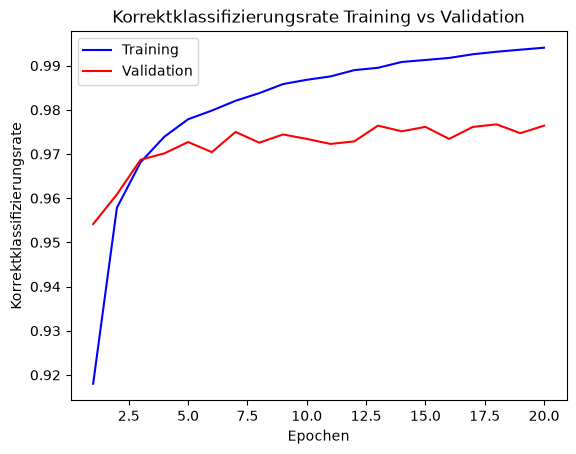

In [22]:
epochen = [epoche + 1 for epoche in model_history.epoch]
print(epochen)
plt.plot(epochen, acc, 'b', label="Training")
plt.plot(epochen, val_acc, 'r', label="Validation")

plt.title("Korrektklassifizierungsrate Training vs Validation")
plt.xlabel("Epochen")
plt.ylabel("Korrektklassifizierungsrate")
plt.legend()

plt.show()

In [23]:
# Bewertet das trainierte Modell auf den 10.000 Testbildern, die beim Training nicht verwendet wurden.
# Theorie: Die Test-Accuracy schätzt, wie gut das Modell auf bisher unbekannte Beispiele derselben Datenverteilung generalisiert.
# X_test wurde oben bereits auf (10000, 784) abgeflacht und auf [0, 1] skaliert.
# Nur y_test benötigt to_categorical: Die Labels wurden oben bereits in zehnstellige One-Hot-Vektoren umgewandelt.
# X_test enthält Pixelmerkmale und wird deshalb nicht mit to_categorical umgewandelt.
# Eine erneute One-Hot-Kodierung oder Division durch 255 würde die bereits aufbereiteten Daten verfälschen.

# Prüft die erwarteten Formen: ein Vektor mit 784 Pixelwerten und zehn Zielwerten pro Testbild.
assert X_test.shape == (10000, 784)
assert y_test.shape == (10000, 10)

# Berechnet die kategoriale Kreuzentropie (Loss) und die beim compile konfigurierte Accuracy.
# Theorie: evaluate führt Vorhersagen und den Vergleich mit den richtigen Labels durch, ohne die Modellgewichte zu verändern.
# batch_size=32 verarbeitet die Bilder in Gruppen; verbose=0 unterdrückt die Fortschrittsanzeige.
test_loss, test_accuracy = model.evaluate(X_test, y_test, batch_size=32)

# Gibt den Testverlust aus: kleinere Werte bedeuten eine bessere Bewertung der richtigen Klassen durch das Modell.
print(f"Test-Loss: {test_loss:.4f}")
# Zeigt den Anteil korrekt klassifizierter unbekannter Bilder als Prozentwert mit zwei Nachkommastellen.
# Theorie: Die Klasse mit der höchsten Softmax-Wahrscheinlichkeit wird mit der richtigen Klasse verglichen.
print(f"Test-Accuracy: {test_accuracy:.2%}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9753 - loss: 0.1133
Test-Loss: 0.1133
Test-Accuracy: 97.53%


## Vorhersage eines einzelnen Bildes ##
1 Bild von der Shape(28,28) in die Shape (,789) transformieren
2 Da predict eine Matrix als Argument erfordert, ist das Bild dann noch in die 2.Dimension zu schieben mit reshape(1,-1)
3 predict mit dem Bild ausführen. Ergebnis ist dann ligischerweise wieder eine Matrix

In [25]:
X_test[:10]

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(10, 784), dtype=float32)

In [26]:
# -1 macht automatisch aus einer Matrix einen Vektor
# entspircht in unserem Fall: reshape(784,)
X_test[0].reshape(1,-1)
X_test.shape

(10000, 784)

In [27]:
# Predict erwartet immer eine Matrix (none, 784) => (n,784) es will nicht ein Beispiel sondern n Viele
y_pred = model.predict(X_test[:10].reshape(10,-1))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step


In [28]:
y_pred

array([[9.11887211e-13, 1.84701953e-16, 1.54370683e-10, 1.13101453e-06,
        8.83667370e-18, 1.64939572e-11, 1.98413538e-23, 9.99998808e-01,
        1.42141410e-09, 1.02012685e-07],
       [5.75520879e-18, 2.48227622e-15, 1.00000000e+00, 1.81027531e-08,
        1.04295700e-32, 1.28629651e-13, 5.14977821e-16, 4.30065141e-31,
        4.96601752e-17, 8.05840686e-30],
       [4.53958017e-11, 9.99898672e-01, 3.39025723e-06, 3.35839758e-07,
        6.64073639e-07, 1.94639038e-09, 8.29902014e-09, 6.80202356e-05,
        2.89852615e-05, 9.44266110e-10],
       [9.99999523e-01, 1.81140626e-17, 2.70381911e-10, 1.56731861e-09,
        1.45556553e-11, 7.81842413e-09, 5.01081615e-07, 3.99767684e-11,
        8.14407068e-14, 9.37250455e-09],
       [5.17761407e-07, 6.56613588e-15, 3.00764913e-10, 9.26494385e-12,
        9.99845386e-01, 3.32809752e-10, 5.44559109e-09, 4.43207273e-06,
        1.46715995e-09, 1.49737694e-04],
       [1.65307221e-13, 9.99943137e-01, 8.94251073e-09, 3.65948671e-09,
   

In [29]:
np.argmax(y_pred, axis=1)

array([7, 2, 1, 0, 4, 1, 4, 9, 6, 9])

In [30]:
model.save('./mnist_model')
# .keras => in zip verwandeln
# config.json enthält die Architektur
# model.weights.h5 enthält die gelernten Gewichte/Parameter. (Diese Datei wrid geladen, wenn man nur die Gewichte benätigt)
# 

ValueError: Invalid filepath extension for saving. Please add either a `.keras` extension for the native Keras format (recommended) or a `.h5` extension. Use `model.export(filepath)` if you want to export a SavedModel for use with TFLite/TFServing/etc. Received: filepath=./mnist_model.

In [ ]:
#